In [1]:
# Put the repository root on sys.path, wherever the kernel was started from.
import os, sys

def _find_repo_root():
    _pkgs = ("genotyping", "pipelines", "screening", "sequencing")
    for _cand in [os.getcwd(), *sys.path]:
        if not _cand:
            continue
        _d = os.path.abspath(_cand)
        while True:
            if all(os.path.isdir(os.path.join(_d, _p)) for _p in _pkgs):
                return _d
            _parent = os.path.dirname(_d)
            if _parent == _d:
                break
            _d = _parent
    return None

_repo_root = _find_repo_root()
if _repo_root and _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

import A14_03_config as config
from pathlib import Path
import sys
import os
import multiprocessing as mp
import importlib

import pandas as pd
import os
# import seaborn as sns
import matplotlib.pyplot as plt

from pipelines import common_tasks

# Reload the modules
importlib.reload(config)
importlib.reload(common_tasks)

from screening import screen_utils

NAS_folder = "/mnt/G_Pharma/Users/tfang/Cell_Screen/PW_A14-03_Screen/output_transfered"
os.makedirs(NAS_folder, exist_ok=True)

In [2]:
lib=config.get_library()
lib 

,Unnamed: 0,finalname,lib_section,specific_primerpart,barcode,spacer,target rv,oligofinal,llength,barcode_verified,target_site_rc_PlusTAM,target_site_PlusTAM,target_site,TAM
0,NaN,LIB_A14-01,LIB-A14-01,NaN,GCACGTA,TTCCAGTTAAGGAGAGGAAT,ATTCCTCTCCTTAACTGGAAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATTCCAGTTAAGGAGAGGAAT...,209,GCACGTA,ATTCCTCTCCTTAACTGGAAATCTT,AAGATTTCCAGTTAAGGAGAGGAAT,TTCCAGTTAAGGAGAGGAAT,AAGAT
1,NaN,LIB_A14-01,LIB-A14-01,NaN,CGACGTC,TGAAAACTTCAGTGATATCG,CGATATCACTGAAGTTTTCAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATGAAAACTTCAGTGATATCG...,209,CGACGTC,CGATATCACTGAAGTTTTCAATCTT,AAGATTGAAAACTTCAGTGATATCG,TGAAAACTTCAGTGATATCG,AAGAT
2,NaN,LIB_A14-01,LIB-A14-01,NaN,GATGTTC,GGCAGAAGGTACACAGCAAC,GTTGCTGTGTACCTTCTGCCATCTT,CGCGACTTTAGTCGTGTGAGGTTCAAGGCAGAAGGTACACAGCAAC...,209,GATGTTC,GTTGCTGTGTACCTTCTGCCATCTT,AAGATGGCAGAAGGTACACAGCAAC,GGCAGAAGGTACACAGCAAC,AAGAT
3,NaN,LIB_A14-01,LIB-A14-01,NaN,AGGAAAT,TATAGTTAAAAATATGCCAC,GTGGCATATTTTTAACTATAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATATAGTTAAAAATATGCCAC...,209,AGGAAAT,GTGGCATATTTTTAACTATAATCTT,AAGATTATAGTTAAAAATATGCCAC,TATAGTTAAAAATATGCCAC,AAGAT
4,NaN,LIB_A14-01,LIB-A14-01,NaN,GTCGCCT,AAGGAGATTATACCCAGAAT,ATTCTGGGTATAATCTCCTTATCTT,CGCGACTTTAGTCGTGTGAGGTTCAAAAGGAGATTATACCCAGAAT...,209,GTCGCCT,ATTCTGGGTATAATCTCCTTATCTT,AAGATAAGGAGATTATACCCAGAAT,AAGGAGATTATACCCAGAAT,AAGAT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
479,NaN,LIB_A14-01,LIB-A14-01,NaN,GTGACTT,TTAGGTAAATAAAGATCTCT,AGAGATCTTTATTTACCTAACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATTAGGTAAATAAAGATCTCT...,209,GTGACTT,AGAGATCTTTATTTACCTAACTCAA,TTGAGTTAGGTAAATAAAGATCTCT,TTAGGTAAATAAAGATCTCT,TTGAG
480,NaN,LIB_A14-01,LIB-A14-01,NaN,TGTCCTA,TTCTACTCAAGCCGCTCTAC,GTAGAGCGGCTTGAGTAGAACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATTCTACTCAAGCCGCTCTAC...,209,TGTCCTA,GTAGAGCGGCTTGAGTAGAACTCAA,TTGAGTTCTACTCAAGCCGCTCTAC,TTCTACTCAAGCCGCTCTAC,TTGAG
481,NaN,LIB_A14-01,LIB-A14-01,NaN,GCAACCA,GAAGAGGACCTGGGAGATGA,TCATCTCCCAGGTCCTCTTCCTCAA,CGCGACTTTAGTCGTGTGAGGTTCAAGAAGAGGACCTGGGAGATGA...,209,GCAACCA,TCATCTCCCAGGTCCTCTTCCTCAA,TTGAGGAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,TTGAG
482,NaN,LIB_A14-01,LIB-A14-01,NaN,GGTAACG,TATTATATATGAGTTCACTG,CAGTGAACTCATATATAATACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATATTATATATGAGTTCACTG...,209,GGTAACG,CAGTGAACTCATATATAATACTCAA,TTGAGTATTATATATGAGTTCACTG,TATTATATATGAGTTCACTG,TTGAG


In [3]:
samples= config.get_samples()
print(samples.shape)
abe_samples=config.get_abe_samples()
print(abe_samples.shape)
abe_samples

(36, 10)
(18, 10)


,sample_name,sequencing_name,bioreplicate,replicate,file_name_R1,file_name_R2,editor,is_ctrl,lib_section,edit_type
0,A14-03_Sample-1_TnpB-WT_ABE_LIB-A14-01_rep1,Sample-1,TnpB-WT_ABE_LIB-A14-01,1,Sample-1_S1_L001_R1_001.fastq.gz,Sample-1_S1_L001_R2_001.fastq.gz,TnpB-WT_ABE,no,LIB-A14-01,ABE
1,A14-03_Sample-2_TnpB-pPW264_ABE_LIB-A14-01_rep1,Sample-2,TnpB-pPW264_ABE_LIB-A14-01,1,Sample-2_S2_L001_R1_001.fastq.gz,Sample-2_S2_L001_R2_001.fastq.gz,TnpB-pPW264_ABE,no,LIB-A14-01,ABE
2,A14-03_Sample-3_TnpB-pPW265_ABE_LIB-A14-01_rep1,Sample-3,TnpB-pPW265_ABE_LIB-A14-01,1,Sample-3_S3_L001_R1_001.fastq.gz,Sample-3_S3_L001_R2_001.fastq.gz,TnpB-pPW265_ABE,no,LIB-A14-01,ABE
3,A14-03_Sample-4_TnpB-pPW266_ABE_LIB-A14-01_rep1,Sample-4,TnpB-pPW266_ABE_LIB-A14-01,1,Sample-4_S4_L001_R1_001.fastq.gz,Sample-4_S4_L001_R2_001.fastq.gz,TnpB-pPW266_ABE,no,LIB-A14-01,ABE
4,A14-03_Sample-5_TnpB-pPW267_ABE_LIB-A14-01_rep1,Sample-5,TnpB-pPW267_ABE_LIB-A14-01,1,Sample-5_S5_L001_R1_001.fastq.gz,Sample-5_S5_L001_R2_001.fastq.gz,TnpB-pPW267_ABE,no,LIB-A14-01,ABE
5,A14-03_Sample-6_TnpB-WT_ABE_LIB-A14-01_rep2,Sample-6,TnpB-WT_ABE_LIB-A14-01,2,Sample-6_S6_L001_R1_001.fastq.gz,Sample-6_S6_L001_R2_001.fastq.gz,TnpB-WT_ABE,no,LIB-A14-01,ABE
6,A14-03_Sample-7_TnpB-pPW264_ABE_LIB-A14-01_rep2,Sample-7,TnpB-pPW264_ABE_LIB-A14-01,2,Sample-7_S7_L001_R1_001.fastq.gz,Sample-7_S7_L001_R2_001.fastq.gz,TnpB-pPW264_ABE,no,LIB-A14-01,ABE
7,A14-03_Sample-8_TnpB-pPW265_ABE_LIB-A14-01_rep2,Sample-8,TnpB-pPW265_ABE_LIB-A14-01,2,Sample-8_S8_L001_R1_001.fastq.gz,Sample-8_S8_L001_R2_001.fastq.gz,TnpB-pPW265_ABE,no,LIB-A14-01,ABE
8,A14-03_Sample-9_TnpB-pPW266_ABE_LIB-A14-01_rep2,Sample-9,TnpB-pPW266_ABE_LIB-A14-01,2,Sample-9_S9_L001_R1_001.fastq.gz,Sample-9_S9_L001_R2_001.fastq.gz,TnpB-pPW266_ABE,no,LIB-A14-01,ABE
9,A14-03_Sample-10_TnpB-pPW267_ABE_LIB-A14-01_rep2,Sample-10,TnpB-pPW267_ABE_LIB-A14-01,2,Sample-10_S10_L001_R1_001.fastq.gz,Sample-10_S10_L001_R2_001.fastq.gz,TnpB-pPW267_ABE,no,LIB-A14-01,ABE


# analysis of the results

In [4]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A14_03_config as config
import pandas as pd
import numpy as np
import os
import sys

import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening import screen_utils

# import A13_config as config

# import sys
# import os
# import multiprocessing as mp
import importlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

# # Reload the modules
importlib.reload(config)
importlib.reload(screen_utils)
# importlib.reload(common_tasks)

<module 'screening.screen_utils' from '/home/tao/code/tnpb-analysis/screening/screen_utils.py'>

In [5]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

def check_A_to_A_or_C(df):
    df['valid_diff_nt'] = df.apply(lambda row: sum(tsl == ts or (tsl == 'A' and ts in ['C', 'G']) for tsl, ts in zip(row['target_site_lib'], row['most_common_diff_target_site'])) if pd.notna(row['most_common_diff_target_site']) else 20, axis=1)
    return df

# check come quality stats

In [6]:
import pandas as pd
from pathlib import Path

# Assuming config.result_dir is a Path object
csv_files = list(config.result_dir.glob("*.csv"))

# Read and concatenate all CSV files
read_stats = pd.concat([pd.read_csv(file, header=None, index_col=0).squeeze("columns") for file in csv_files], axis=1).T.reset_index(drop=True)

print(f"Total files read: {len(csv_files)}")
read_stats

# read_stats=pd.read_excel(config.result_dir / 'read_stats.xlsx')
# read_stats

Total files read: 36


,NaN,sample_name,num_reads,r1_frac_anchor_error,r2_frac_anchor_error
0,0,A14-03_Sample-13_TnpB-pPW265_ABE_LIB-A14-01_rep3,665081,0.01646115285205862,0.018486470069059256
1,0,A14-03_Sample-39_TnpB-pPW258_nuclease_LIB-A14-...,416278,0.015198977606311167,0.01881194778489375
2,0,A14-03_Sample-14_TnpB-pPW266_ABE_LIB-A14-01_rep3,691579,0.016588126591466773,0.018086147786442328
3,0,A14-03_Sample-20_TnpB-pPW226_nuclease_LIB-A14-...,578909,0.018795700187766988,0.018075379722892543
4,0,A14-03_Sample-37_TnpB-pPW222_nuclease_LIB-A14-...,677892,0.015110076531364878,0.024118886194261033
5,0,A14-03_Sample-18_TnpB-WT_nuclease_LIB-A14-01_rep1,560727,0.015073288784025024,0.018714989647368504
6,0,A14-03_Sample-21_TnpB-pPW258_nuclease_LIB-A14-...,559531,0.015359291978460532,0.018872948951890064
7,0,A14-03_Sample-22_TnpB-pPW259_nuclease_LIB-A14-...,564212,0.020026160379431845,0.01887233876627934
8,0,A14-03_Sample-9_TnpB-pPW266_ABE_LIB-A14-01_rep2,859342,0.015571216116517055,0.01926939449020297
9,0,A14-03_Sample-41_TnpB-pPW260_nuclease_LIB-A14-...,841398,0.015191383863522376,0.01966132555580118


In [7]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import warnings

## check reads level quality

In [8]:
def get_abe_samples(config,sample_name_column='sample_name',editor_column='editor'):
    samples = config.get_samples()
    return samples.loc[samples[editor_column].str.contains('ABE'),:]

def collect_abe_read_edit_rates(config,sample_name_column='sample_name',editor_column='editor',control_column='control_yes_no'):
    """ Collect edit rates for all samples"""
    print('Collecting ABE edit rates for all samples')
    #samples = get_abe_samples(config,sample_name_column,editor_column)
    # samples=config.get_samples()
    samples=config.get_abe_samples()
    all_sample_rates = pd.concat(
        [
            pd.read_csv(config.edit_rate(f'{sample[sample_name_column]}-reads-editedrates-unfiltered'), index_col=0).assign(
                editor=sample[editor_column],
                sample_name=sample[sample_name_column],
                is_ctrl=sample[control_column],
                replicate=sample["replicate"],
            )
            for _,sample in samples.iterrows()
        ]
    ).reset_index(drop=True)
    all_sample_rates.loc[:, 'is_ctrl'] = all_sample_rates.is_ctrl == 'yes'
    return all_sample_rates
    #all_sample_rates.to_csv(config.edit_rate('all-abe-samples-reads-editedrates-unfiltered-not-normalized'))
    

In [9]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=collect_abe_read_edit_rates(config,sample_name_column='sample_name',
                                                                                        editor_column='editor',control_column="is_ctrl")
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)

all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(8519, 12)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.009828,407,ATCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,A14-03_Sample-1_TnpB-WT_ABE_LIB-A14-01_rep1,False,1
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.032787,61,TTAAAGAAAAATTCCATGCC,TTAAAGAAAAATTCCTTGCC,"[3, 4, 5, 7, 8, 9, 10, 11]",TnpB-WT_ABE,A14-03_Sample-1_TnpB-WT_ABE_LIB-A14-01_rep1,False,1
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.009202,3260,CAAAGAAGTTATACTCATTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,A14-03_Sample-1_TnpB-WT_ABE_LIB-A14-01_rep1,False,1


In [10]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.merge(samples[['sample_name','bioreplicate','lib_section']],on='sample_name', how='left',
                                                                     )
all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"] = all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].str.split("Sample-").str[-1]
all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"] = all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].apply(lambda x: "_".join(x.split("_")[1:]))
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(8519, 14)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.009828,407,ATCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.032787,61,TTAAAGAAAAATTCCATGCC,TTAAAGAAAAATTCCTTGCC,"[3, 4, 5, 7, 8, 9, 10, 11]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.009202,3260,CAAAGAAGTTATACTCATTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01


In [11]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.merge(lib[['barcode','spacer']], on='barcode', how='left',suffixes=('', '_LIB'))
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(8519, 15)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.009828,407,ATCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTCTTTGAGACTTGGCATGC
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.032787,61,TTAAAGAAAAATTCCATGCC,TTAAAGAAAAATTCCTTGCC,"[3, 4, 5, 7, 8, 9, 10, 11]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTAAAGAAAAATTCCTTGCC
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.009202,3260,CAAAGAAGTTATACTCATTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC


In [12]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.\
    loc[all_abe_samples_reads_editedrates_unfiltered_not_normalized['num_reads'] >= 100]     # 100,
print(all_abe_samples_reads_editedrates_not_normalized.shape)
all_abe_samples_reads_editedrates_not_normalized.head(n=3)

(7242, 15)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.009828,407,ATCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTCTTTGAGACTTGGCATGC
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.009202,3260,CAAAGAAGTTATACTCATTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC
3,AAACAAA,TATAGTTAAAAATATGCCAC,TTAAT,0.009286,1723,AATAGTTAAAAATATGCCAC,TATAGTTAAAAATATGCCAC,"[2, 4, 8, 9, 10, 11, 12, 14, 19]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TATAGTTAAAAATATGCCAC


In [13]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized_pivot_df = all_abe_samples_reads_editedrates_not_normalized.pivot_table(index=['spacer', 'TAM', "target_site_lib"],
                                           columns='sample_name',
                                           values=['frac_reads_edited','num_reads'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns = ['_'.join(col).strip() for col in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns.values]

print(all_abe_samples_reads_editedrates_not_normalized_pivot_df.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df

(466, 39)


,spacer_,TAM_,target_site_lib_,frac_reads_edited_Mock_LIB-A14-01_rep1,frac_reads_edited_Mock_LIB-A14-01_rep2,frac_reads_edited_Mock_LIB-A14-01_rep3,frac_reads_edited_TnpB-267_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep3,...,num_reads_TnpB-pPW264_ABE_LIB-A14-01_rep2,num_reads_TnpB-pPW264_ABE_LIB-A14-01_rep3,num_reads_TnpB-pPW265_ABE_LIB-A14-01_rep1,num_reads_TnpB-pPW265_ABE_LIB-A14-01_rep2,num_reads_TnpB-pPW265_ABE_LIB-A14-01_rep3,num_reads_TnpB-pPW266_ABE_LIB-A14-01_rep1,num_reads_TnpB-pPW266_ABE_LIB-A14-01_rep2,num_reads_TnpB-pPW266_ABE_LIB-A14-01_rep3,num_reads_TnpB-pPW267_ABE_LIB-A14-01_rep1,num_reads_TnpB-pPW267_ABE_LIB-A14-01_rep2
0,AAGGAGATTATACCCAGAAT,AAGAT,AAGGAGATTATACCCAGAAT,0.006369,0.008996,0.006211,0.010274,0.004196,0.018987,0.010901,...,1354.0,2564.0,1221.0,1574.0,1924.0,2098.0,1250.0,758.0,1125.0,1480.0
1,AAGGAGATTATACCCAGAAT,ACGAT,AAGGAGATTATACCCAGAAT,0.008299,0.005236,0.007536,0.011065,0.011650,0.005063,0.004255,...,1179.0,884.0,801.0,2971.0,918.0,1106.0,1694.0,928.0,264.0,714.0
2,AAGGAGATTATACCCAGAAT,AGGAT,AAGGAGATTATACCCAGAAT,0.011713,0.006051,0.004360,0.010079,0.004211,0.007459,0.007242,...,1344.0,1292.0,2178.0,808.0,154.0,1695.0,889.0,987.0,1051.0,495.0
3,AAGGAGATTATACCCAGAAT,ATGAT,AAGGAGATTATACCCAGAAT,0.013473,0.006618,0.006482,0.009740,0.024777,0.043725,0.163096,...,2082.0,1960.0,1501.0,1007.0,1912.0,1941.0,1291.0,1086.0,1427.0,3090.0
4,AAGGAGATTATACCCAGAAT,CAGAT,AAGGAGATTATACCCAGAAT,0.009098,0.011819,0.021073,0.007402,0.017336,0.012240,0.023829,...,893.0,1194.0,773.0,896.0,226.0,657.0,2164.0,832.0,479.0,284.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
461,TTCTTTGAGACTTGGCATGC,TTGAA,TTCTTTGAGACTTGGCATGC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1763.0,NaN,129.0,NaN,NaN,NaN,139.0,NaN,NaN,NaN
462,TTCTTTGAGACTTGGCATGC,TTGAC,TTCTTTGAGACTTGGCATGC,0.010638,0.007576,0.007174,0.003623,0.016129,0.006098,0.019455,...,799.0,140.0,289.0,315.0,425.0,149.0,392.0,262.0,164.0,265.0
463,TTCTTTGAGACTTGGCATGC,TTGAG,TTCTTTGAGACTTGGCATGC,0.007273,0.000000,0.006944,0.012862,0.009404,0.000000,0.012000,...,199.0,458.0,399.0,319.0,2688.0,298.0,934.0,554.0,534.0,158.0
464,TTCTTTGAGACTTGGCATGC,TTGAT,TTCTTTGAGACTTGGCATGC,0.003077,0.028070,0.004202,NaN,0.019108,0.016129,0.000000,...,348.0,746.0,422.0,1528.0,337.0,451.0,262.0,441.0,451.0,274.0


In [14]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

editor_columns=sorted([l for l in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns if "frac_reads" in l])

all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim=all_abe_samples_reads_editedrates_not_normalized_pivot_df.loc[:,list(editor_columns)]
print(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim

(466, 18)


,frac_reads_edited_Mock_LIB-A14-01_rep1,frac_reads_edited_Mock_LIB-A14-01_rep2,frac_reads_edited_Mock_LIB-A14-01_rep3,frac_reads_edited_TnpB-267_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW264_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW264_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW264_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW265_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW265_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW265_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW266_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW266_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW266_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW267_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW267_ABE_LIB-A14-01_rep2
0,0.006369,0.008996,0.006211,0.010274,0.004196,0.018987,0.010901,0.007843,0.070162,0.016771,0.004095,0.019695,0.015073,0.035272,0.008000,0.032982,0.013333,0.008784
1,0.008299,0.005236,0.007536,0.011065,0.011650,0.005063,0.004255,0.009590,0.211196,0.066742,0.002497,0.007742,0.064270,0.036166,0.011806,0.009698,0.011364,0.012605
2,0.011713,0.006051,0.004360,0.010079,0.004211,0.007459,0.007242,0.002841,0.007440,0.010836,0.007346,0.004950,0.032468,0.008260,0.005624,0.022290,0.008563,0.010101
3,0.013473,0.006618,0.006482,0.009740,0.024777,0.043725,0.163096,0.012613,0.251201,0.178571,0.277149,0.009930,0.079498,0.126739,0.100697,0.014733,0.005606,0.007443
4,0.009098,0.011819,0.021073,0.007402,0.017336,0.012240,0.023829,0.008929,0.070549,0.343384,0.011643,0.013393,0.000000,0.012177,0.007856,0.009615,0.008351,0.010563
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
461,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.002836,NaN,0.000000,NaN,NaN,NaN,0.014388,NaN,NaN,NaN
462,0.010638,0.007576,0.007174,0.003623,0.016129,0.006098,0.019455,0.018519,0.008761,0.035714,0.020761,0.003175,0.002353,0.013423,0.010204,0.007634,0.018293,0.018868
463,0.007273,0.000000,0.006944,0.012862,0.009404,0.000000,0.012000,0.009446,0.010050,0.004367,0.010025,0.003135,0.006324,0.006711,0.001071,0.009025,0.003745,0.006329
464,0.003077,0.028070,0.004202,NaN,0.019108,0.016129,0.000000,0.005435,0.005747,0.068365,0.066351,0.002618,0.008902,0.039911,0.007634,0.034014,0.004435,0.003650


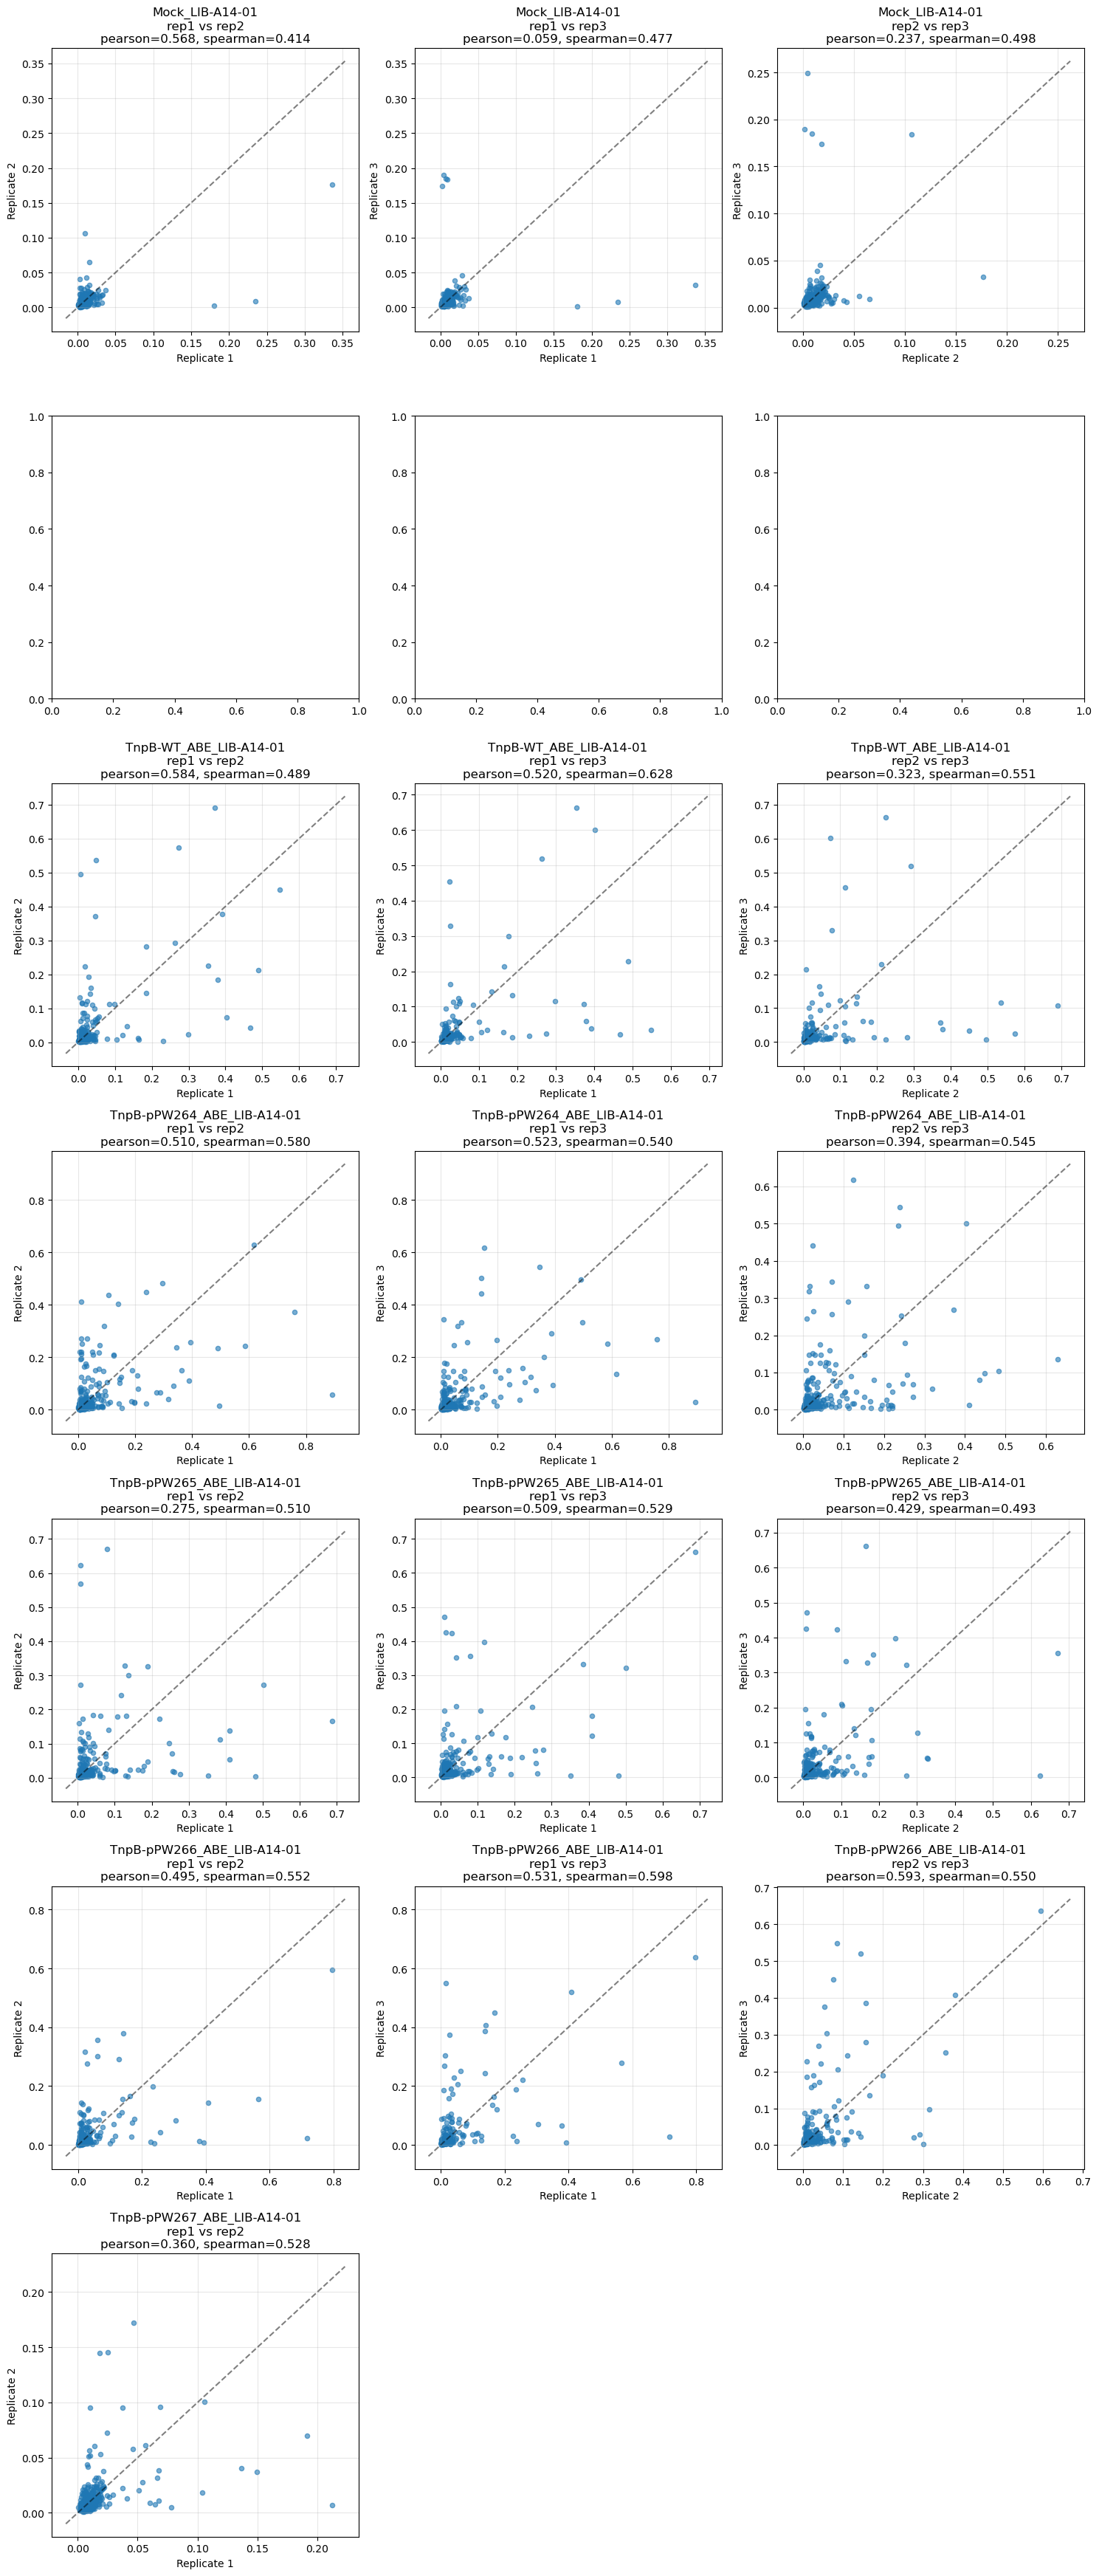

In [15]:
from scipy.stats import pearsonr, spearmanr

import matplotlib.pyplot as plt

def plot_paired_correlations(df,corr_edit_thres=0.3):
    """df have edit rate for different editor in different replicate, each column is one replice .
    column name are like this "frac_reads_edited_Mock_130_ABE_LIB-130_d10_rep1", "frac_reads_edited_Mock_130_ABE_LIB-130_d10_rep1"
    now i want to draw scatter plot between different replicates, for each editor, the plot in in row
    and show pearsonand spearman correlation in the figure legened

    for corr_edit_thres, only plot the replicates pair with correlation higher than this thres
    since editors have no/low editing for most of pams

    """
    # Extract editor names from column names
    editors = {}
    for col in df.columns:
        if col.startswith('frac_reads_edited_'):
            # Extract editor name (everything between 'frac_reads_edited_' and the last '_rep')
            editor_part = col.replace('frac_reads_edited_', '')
            editor_name = '_'.join(editor_part.split('_')[:-1])  # Remove the last _repX part
            if editor_name not in editors:
                editors[editor_name] = []
            editors[editor_name].append(col)

    # Create subplots - each row for one editor, columns for pairwise comparisons
    n_editors = len(editors)
    max_pairs = max(len(cols) * (len(cols) - 1) // 2 for cols in editors.values() if len(cols) > 1)

    fig, axes = plt.subplots(n_editors, max_pairs, figsize=(5*max_pairs, 5*n_editors))
    if n_editors == 1:
        axes = axes.reshape(1, -1)
    elif max_pairs == 1:
        axes = axes.reshape(-1, 1)

    for row_idx, (editor, columns) in enumerate(editors.items()):
        if len(columns) < 2:
            continue

        # Get all pairs of replicates
        pair_idx = 0
        for i in range(len(columns)):
            for j in range(i+1, len(columns)):
                col1, col2 = columns[i], columns[j]

                # Get data for correlation (remove NaN values)
                mask = ~(df[col1].isna() | df[col2].isna())
                x_data = df[col1][mask]
                y_data = df[col2][mask]

                #for x_data and y data. filter to get ones that both x_data and y_data > corr_edit_thres
                mask_corr_thres = (x_data > corr_edit_thres) & (y_data > corr_edit_thres) # (x_data > corr_edit_thres) | (y_data > corr_edit_thres)
                x_data = x_data[mask_corr_thres]
                y_data = y_data[mask_corr_thres]

                if len(x_data) > 0:
                    # Calculate correlations
                    pearson_r, pearson_p = pearsonr(x_data, y_data)
                    spearman_r, spearman_p = spearmanr(x_data, y_data)

                    # Plot scatter
                    ax = axes[row_idx, pair_idx]
                    ax.scatter(x_data, y_data, alpha=0.6, s=20)

                    # Extract replicate numbers
                    rep1 = col1.split('_rep')[-1]
                    rep2 = col2.split('_rep')[-1]

                    ax.set_xlabel(f'Replicate {rep1}')
                    ax.set_ylabel(f'Replicate {rep2}')
                    ax.set_title(f'{editor}\nrep{rep1} vs rep{rep2}\npearson={pearson_r:.3f}, spearman={spearman_r:.3f}')
                    ax.grid(True, alpha=0.3)

                    # Add diagonal line
                    max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
                    min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
                    ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)

                    pair_idx += 1

        # Hide unused subplots in this row
        for col_idx in range(pair_idx, max_pairs):
            axes[row_idx, col_idx].set_visible(False)

    plt.tight_layout()
    plt.show()

plot_paired_correlations(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim,
                         corr_edit_thres=0.)

# here is correlatoin plot is meaningless, since most TAMs have low editing 

In [16]:


def plot_heatmap_for_bioreplicate(mean_fracs, bioreplicate, vis_edit_thres=0.1, figsize=(8,6), cmap="viridis", save_figure=True, prefix="notNormalized"):

    # Filter for the specified bioreplicate and compute heatmap data
    df_heat = mean_fracs[mean_fracs["bioreplicate"] == bioreplicate].copy()
    df_heat.loc[df_heat['frac_reads_edited'] < vis_edit_thres, 'frac_reads_edited'] = 0
    # Check if all PAMs from config.PAMS are present in df_heat["TAM"]
    missing_pams = set(config.PAMS) - set(df_heat["TAM"].unique())
    if missing_pams:
        # For each missing PAM, add a row with frac_reads_edited set to 0
        df_missing = pd.DataFrame({'TAM': list(missing_pams), 'frac_reads_edited': 0})
        df_heat = pd.concat([df_heat, df_missing], ignore_index=True)
    df_heat["TAM_row"] = df_heat["TAM"].str[:2]
    df_heat["TAM_col"] = df_heat["TAM"].str[-3:]
    pivot_heat = df_heat.pivot_table(index="TAM_row",
                                     columns="TAM_col",
                                     values="frac_reads_edited",
                                     aggfunc="mean").fillna(0)

    # Plot the heatmap
    pivot_heat = pivot_heat.sort_index(key=lambda x: [s[1] + s[0] for s in x], ascending=True)

    plt.figure(figsize=figsize)
    sns.heatmap(pivot_heat, fmt=".3f", cmap=cmap, vmin=0, vmax=1)
    plt.yticks(rotation=0)
    plt.title(f"Heatmap of frac_reads_edited for {bioreplicate}")
    plt.ylabel("First two letters of TAM")
    plt.xlabel("Last three letters of TAM")
    plt.tight_layout()

    #Save the figure to NAS_folder
    if save_figure:
        save_path = os.path.join(NAS_folder, f"{prefix}_heatmap_{bioreplicate}_{vis_edit_thres}.png")
        plt.savefig(save_path)
        plt.show()

mean_fracs_not_normalized = all_abe_samples_reads_editedrates_not_normalized.groupby(['bioreplicate','TAM', 'spacer'])['frac_reads_edited'].mean().reset_index()
mean_fracs_not_normalized.sort_values(by=['bioreplicate','spacer'], inplace=True)
mean_fracs_not_normalized.head(n=30)

,bioreplicate,TAM,spacer,frac_reads_edited
0,Mock_LIB-A14-01,AAGAT,AAGGAGATTATACCCAGAAT,0.007192
19,Mock_LIB-A14-01,ACGAT,AAGGAGATTATACCCAGAAT,0.007024
38,Mock_LIB-A14-01,AGGAT,AAGGAGATTATACCCAGAAT,0.007375
58,Mock_LIB-A14-01,ATGAT,AAGGAGATTATACCCAGAAT,0.008858
77,Mock_LIB-A14-01,CAGAT,AAGGAGATTATACCCAGAAT,0.013997
98,Mock_LIB-A14-01,CCGAT,AAGGAGATTATACCCAGAAT,0.007709
117,Mock_LIB-A14-01,CGGAT,AAGGAGATTATACCCAGAAT,0.007490
136,Mock_LIB-A14-01,CTGAT,AAGGAGATTATACCCAGAAT,0.009887
155,Mock_LIB-A14-01,GAGAT,AAGGAGATTATACCCAGAAT,0.007932
175,Mock_LIB-A14-01,GCGAT,AAGGAGATTATACCCAGAAT,0.003917


In [17]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

In [18]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates,_=normalize_editing_rate_reads(all_abe_samples_reads_editedrates_not_normalized,
        col_normalize_over=['spacer','TAM',"lib_section"],
        col_rate='frac_reads_edited',
        col_control='is_ctrl',
        th_ctrl_missing=1, #
        ctrl_edit_rate_thres=0.2, # 0.3
        ignore_control=['spacer', 'TAM',"lib_section"],
    )

print(all_abe_samples_reads_editedrates.shape)
all_abe_samples_reads_editedrates.head(n=3)

frac_low_num_read_in_control: 0.0. Drop these records
frac_unintendededit_in_control: 0.00411522633744856. Drop these records
43 out of 461 sites are missing control editing rate. drop these sites
(5875, 15)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
1,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.001326,3260,CAAAGAAGTTATACTCATTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC
2,AAACAAA,TATAGTTAAAAATATGCCAC,TTAAT,0.000000,1723,AATAGTTAAAAATATGCCAC,TATAGTTAAAAATATGCCAC,"[2, 4, 8, 9, 10, 11, 12, 14, 19]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TATAGTTAAAAATATGCCAC
3,AAAGGGT,TATTATATATGAGTTCACTG,TTGAC,0.268163,475,AATTATATATGAGTTCACTG,TATTATATATGAGTTCACTG,"[2, 5, 7, 9, 12, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TATTATATATGAGTTCACTG
